# Ejercicio 06 · Autoencoder y VAE
Alexis De La Cruz · 100805370 · INF-8239

Proyecto base LAB10 de Edwin Ramón José Nolasco. Desarrollo y verificaciones con apoyo de Codex. Consulta MODEL_CARD.md y AI_USE_DECLARATION.md.

## Protocolo fijado
Fashion-MNIST completo: 54,000 ajuste, 6,000 validación y 10,000 prueba. Partición y ajuste con semilla42. AE16,6 épocas; VAE2 con β1 y β0.1,8 épocas, lote256. Selección de checkpoint y VAE por **BCE sumada + KL con peso común1 en validación**. Esto evita comparar pérdidas totales con pesos distintos. Arquitecturas del docente: la comparación AE/VAE también difiere en capacidad y tamaño latente; no aísla únicamente KL.

Panel de16 casos de prueba con semilla2026;256 muestras del prior con semilla31415. Referencia de diversidad:256 imágenes de validación con semilla2718. Sin elección manual. Una sola semilla de entrenamiento limita las conclusiones.

In [1]:
from pathlib import Path
import json,sys,subprocess
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
print(sys.executable)
assert sys.version_info[:2]==(3,12)

C:\Users\Alexis De La Cruz\.venvs\u03-gen\.venv\Scripts\python.exe


## Ejecutar desde los archivos oficiales
El comando entrena en un proceso independiente con este mismo intérprete. Verifica SHA-256, registra el checkpoint elegido antes de prueba y produce todas las tablas y figuras.

In [2]:
run=subprocess.run([sys.executable,str(ROOT/'scripts/run_exercise06.py')],capture_output=True,text=True,encoding='utf-8',errors='replace')
print(run.stdout)
if run.returncode: print(run.stderr)
run.check_returncode()

AE 1 val BCE 0.36781
AE 2 val BCE 0.33425
AE 3 val BCE 0.32143
AE 4 val BCE 0.31272
AE 5 val BCE 0.30766
AE 6 val BCE 0.30402
vae_b1 1 val R 286.952 KL 8.839
vae_b1 2 val R 277.812 KL 7.21
vae_b1 3 val R 274.557 KL 6.602
vae_b1 4 val R 272.604 KL 6.414
vae_b1 5 val R 271.224 KL 6.376
vae_b1 6 val R 269.504 KL 6.155
vae_b1 7 val R 268.392 KL 6.055
vae_b1 8 val R 267.049 KL 6.294
vae_b01 1 val R 288.711 KL 41.398
vae_b01 2 val R 275.538 KL 29.25
vae_b01 3 val R 269.919 KL 24.218
vae_b01 4 val R 266.941 KL 22.496
vae_b01 5 val R 265.075 KL 21.218
vae_b01 6 val R 263.416 KL 20.08
vae_b01 7 val R 261.757 KL 19.626
vae_b01 8 val R 260.78 KL 19.29
SELECCI�N PREVIA A TEST: vae_b1
 test_mse  test_ssim   test_kl  evaluation_s  active_latent_units   model  train_s  best_epoch  val_objective  parameters   size_kib  latency_ms  beta
 0.020398   0.536536       NaN      0.333411                  NaN      ae 2.971790           6       0.304024       25888 122.542969    0.008195   NaN
 0.033607   0.417

## Resultado y costos
MSE y SSIM comparan pares originales/reconstrucciones. VAE reconstruye desde μ, sin ruido de muestreo. La inferencia se mide en lotes256, tras calentamiento; no es latencia individual garantizada.

In [3]:
metrics=json.loads((ROOT/'reports/metrics.json').read_text(encoding='utf-8'))
decision=json.loads((ROOT/'reports/decision_locked.json').read_text(encoding='utf-8'))
display(decision)
display(pd.read_csv(ROOT/'reports/main_results.csv').round(5))
display(metrics)

{'chosen': 'vae_b1',
 'criterion': 'menor BCE sumada + KL (peso común 1) en validación; checkpoint por misma regla',
 'seed': 42,
 'time_unix': 1792446740.6250536,
 'before_test': True}

,test_mse,test_ssim,test_kl,evaluation_s,active_latent_units,model,train_s,best_epoch,val_objective,parameters,size_kib,latency_ms,beta
0,0.02040,0.53654,NaN,0.33341,NaN,ae,2.97179,6,0.30402,25888,122.54297,0.00819,NaN
1,0.03361,0.41756,6.27843,0.39072,2.0,vae_b1,7.57207,8,273.34322,202516,832.97070,0.01696,1.0
2,0.03134,0.43879,19.29007,0.51149,2.0,vae_b01,7.40748,8,280.07005,202516,832.97070,0.01556,0.1


{'seed': 42,
 'train': 54000,
 'validation': 6000,
 'test': 10000,
 'split_sha256': 'e1d0864b7fb496c54c49591955b65c82205638333445478817bc477a642b00e0',
 'chosen': 'vae_b1',
 'python': '3.12.12',
 'tensorflow': '2.21.0',
 'system': 'Windows-11-10.0.26300-SP0',
 'gpu_visible': [],
 'total_seconds': 21.81560480000917,
 'peak_working_set_mib': 1180.0234375,
 'diversity': {'n': 256,
  'generated_pairwise_mse': 0.06725838516876495,
  'real_validation_pairwise_mse': 0.17194576115784246,
  'generated_nn_mse_median': 0.008960354141891003,
  'validation_nn_mse_median': 0.014498983044177294,
  'threshold_validation_nn_p05': 0.0046417469857260585,
  'fraction_generated_below_threshold': 0.08984375,
  'nearest_reference_count': 54000,
  'warning': 'Distancias en píxeles: no FID, ni test formal de privacidad o prueba de memorización.'},
 'latent_ae': 16,
 'latent_vae': 2,
 'epochs_ae': 6,
 'epochs_vae': 8,
 'batch_size': 256,
 'test_evaluated_after_selection': True}

## Reconstrucción y KL por separado
BCE del AE se promedia por píxel; BCE del VAE se suma en784 píxeles. KL se suma en2 dimensiones; ambos términos se promedian por imagen. Líneas continuas: validación; discontinuas: ajuste en VAE. No comparar escalas de AE y VAE directamente.

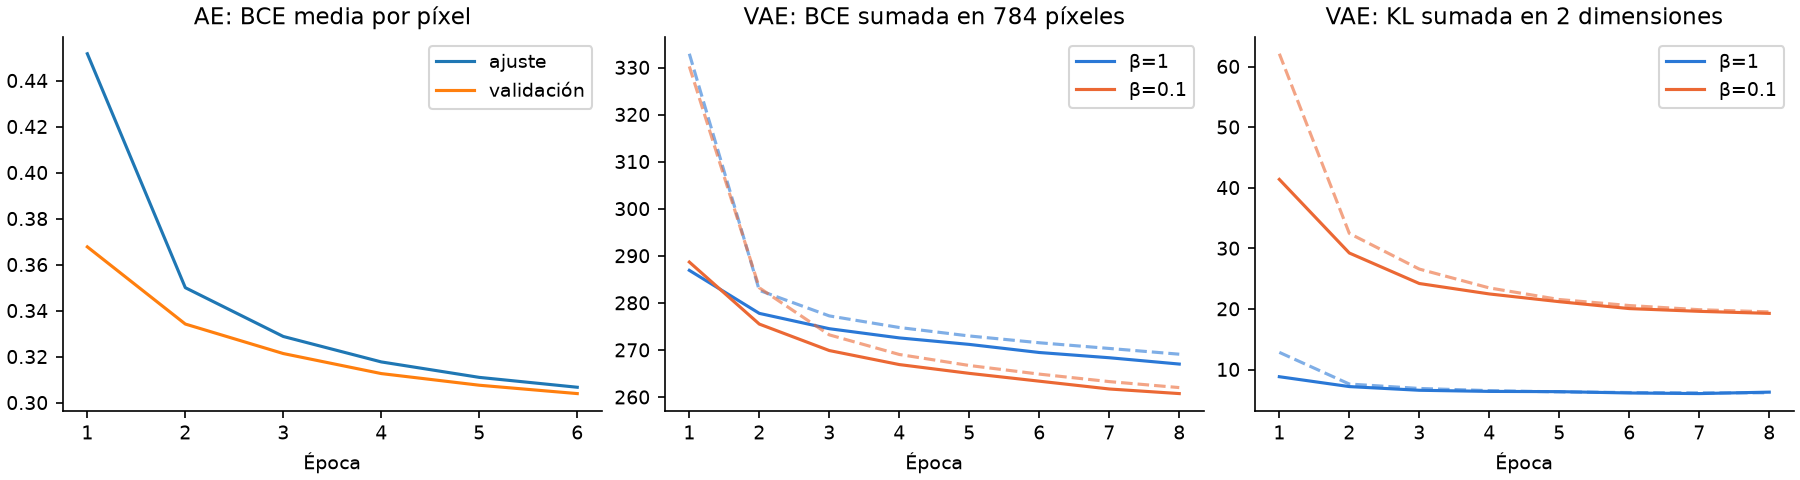

In [4]:
display(Image(filename=str(ROOT/'reports/figures/curves.png')))

## Panel fijo de16 casos
Cada bloque muestra ocho casos: originales, AE, VAE desdeμ y muestras nuevas del prior. La última fila no es una reconstrucción de la original que aparece encima.

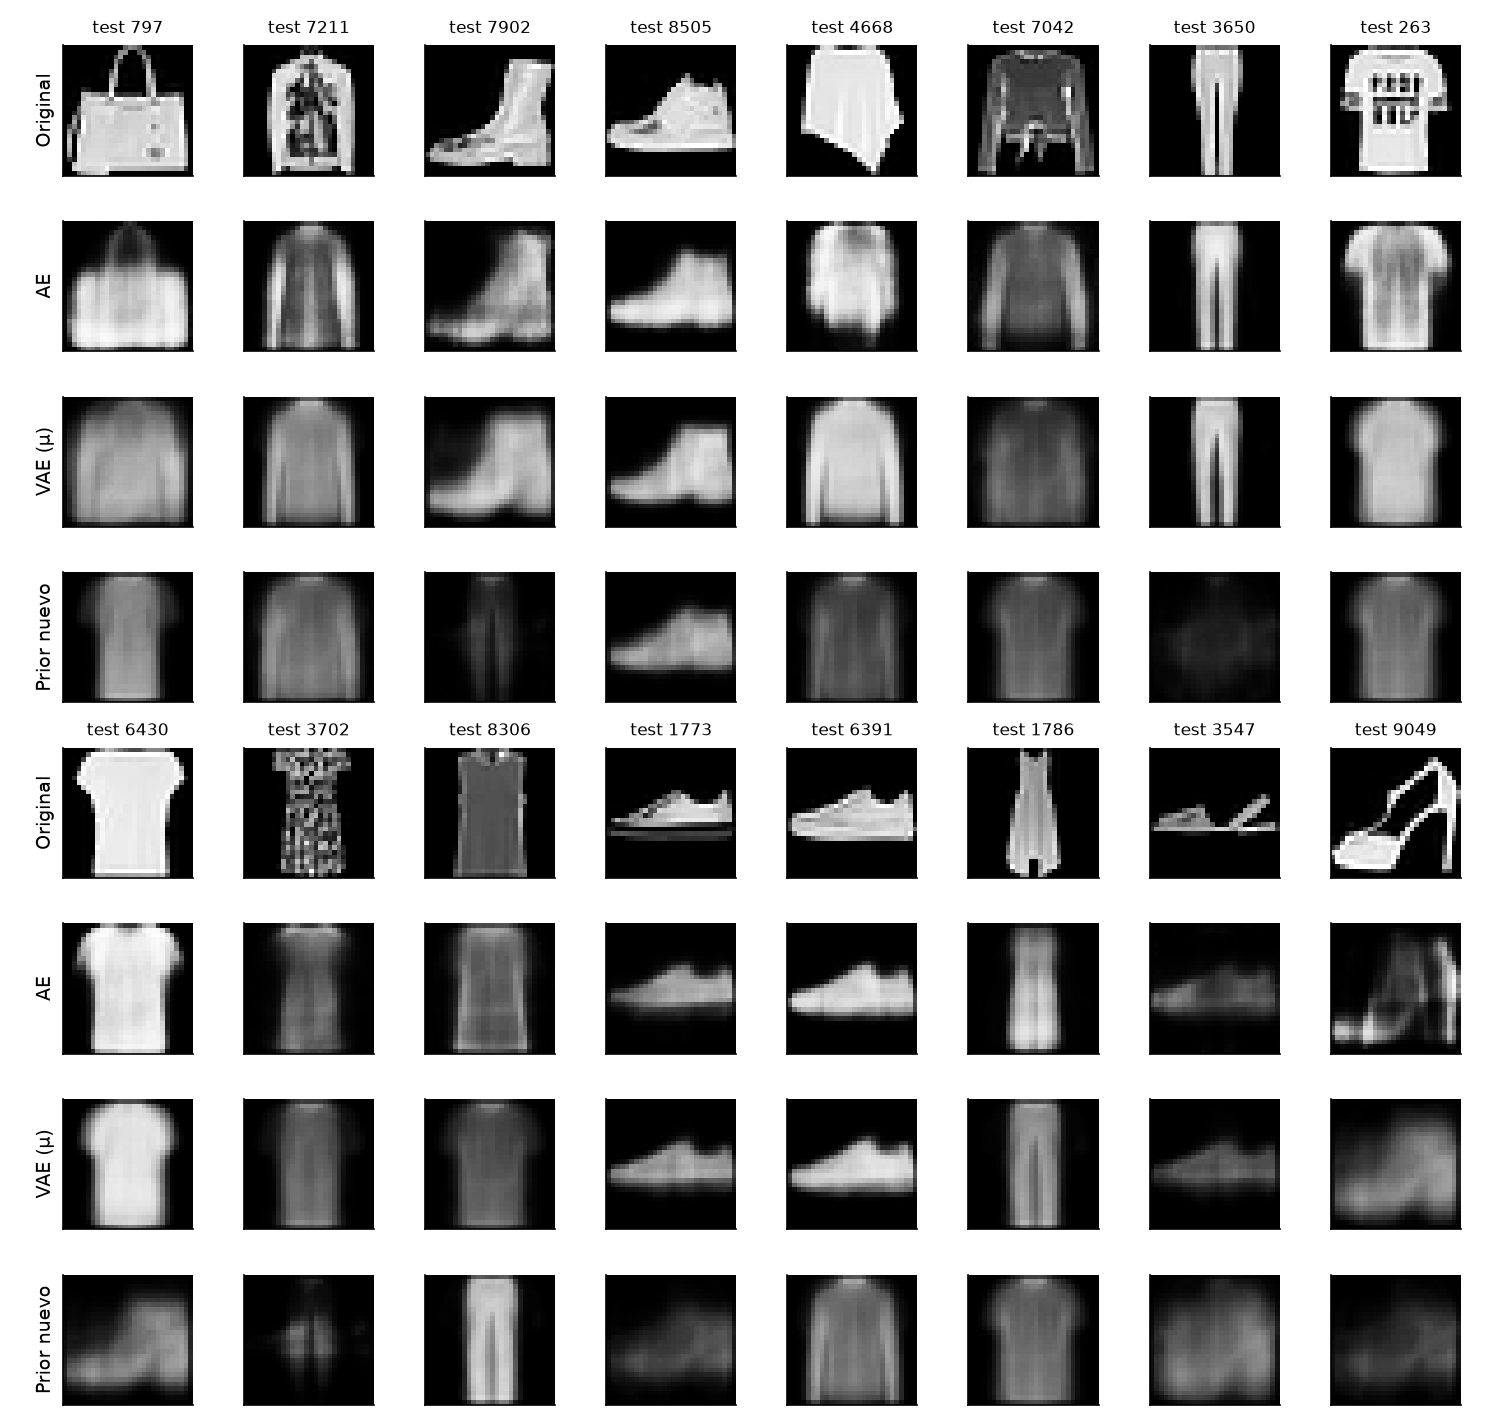

,model,class,n,mse
0,ae,0,1000,0.018578
1,ae,1,1000,0.013976
2,ae,2,1000,0.019387
3,ae,3,1000,0.018636
4,ae,4,1000,0.018009
5,ae,5,1000,0.029807
6,ae,6,1000,0.019320
7,ae,7,1000,0.015582
8,ae,8,1000,0.029583
9,ae,9,1000,0.021106


In [5]:
display(Image(filename=str(ROOT/'reports/figures/panel16.png')))
display(pd.read_csv(ROOT/'reports/errors_by_class.csv'))

## Interpolación y muestras nuevas
La interpolación une las medias latentes de los primeros dos casos del panel. Una transición suave no asigna significado automático a los ejes.

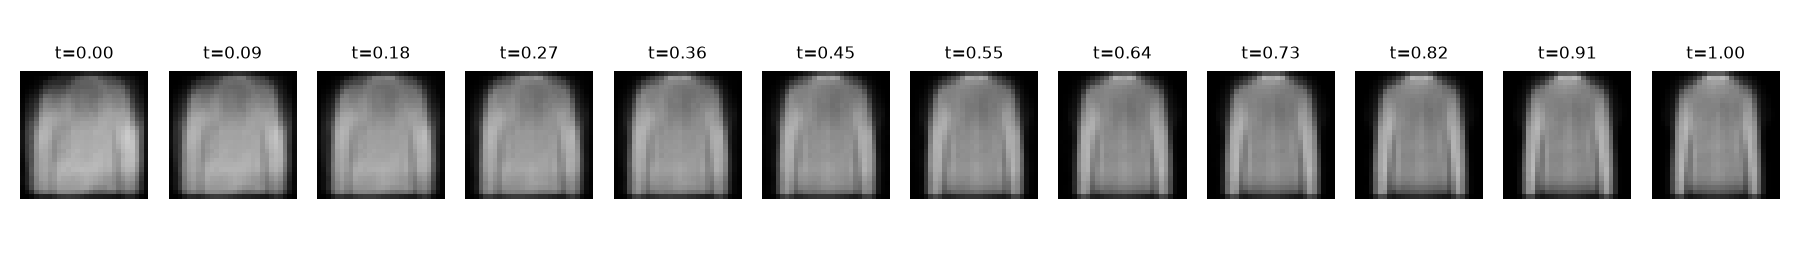

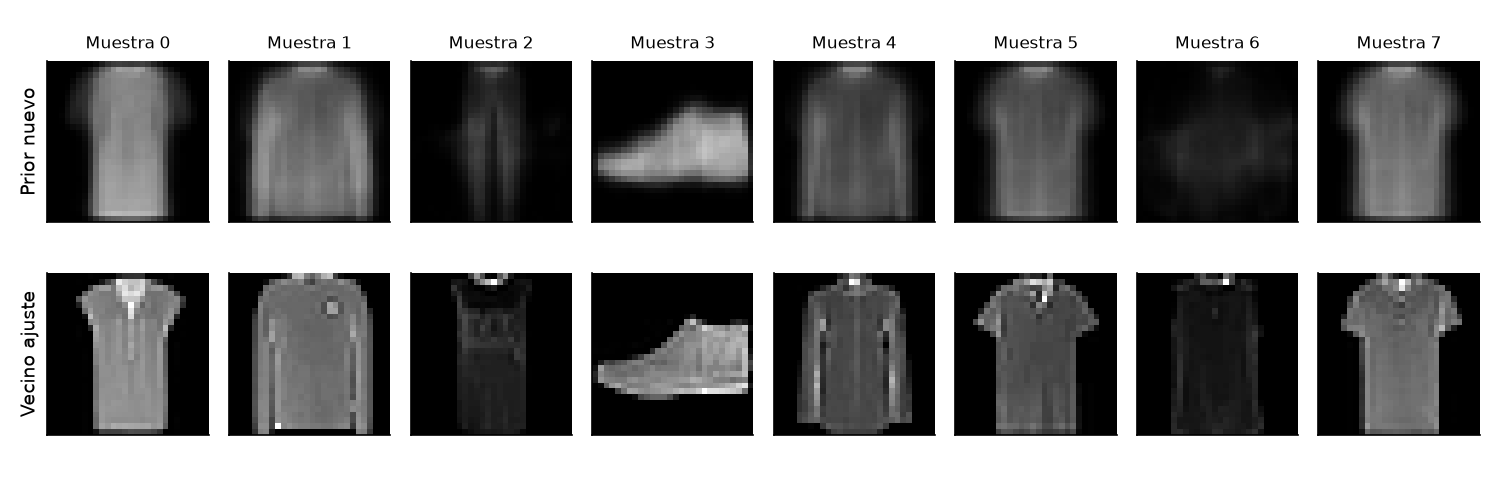

In [6]:
display(Image(filename=str(ROOT/'reports/figures/interpolation.png')))
display(Image(filename=str(ROOT/'reports/figures/neighbors.png')))

## Diversidad y posible memorización
Se buscan vecinos exactos en píxeles contra las54,000 imágenes de ajuste. Se muestran las primeras8 muestras generadas, sin ordenar por similitud. La diversidad es la distancia MSE media entre pares; la referencia real usa validación. El umbral p05 de distancia real a entrenamiento es una señal exploratoria: no es una prueba de privacidad, copia ni FID. No se emparejan arbitrariamente muestras generadas con reales para declarar un error de reconstrucción.

In [7]:
display(pd.Series(metrics['diversity']).to_frame('valor'))
assert metrics['train']+metrics['validation']==60000 and metrics['test']==10000
assert decision['before_test'] and decision['chosen']==metrics['chosen']
assert len(pd.read_csv(ROOT/'reports/main_results.csv'))==3
print('Integridad de partición y selección comprobada.')

,valor
n,256
generated_pairwise_mse,0.067258
real_validation_pairwise_mse,0.171946
generated_nn_mse_median,0.00896
validation_nn_mse_median,0.014499
threshold_validation_nn_p05,0.004642
fraction_generated_below_threshold,0.089844
nearest_reference_count,54000
warning,"Distancias en píxeles: no FID, ni test formal ..."


Integridad de partición y selección comprobada.


## Interpretación
El AE se usa como referencia de reconstrucción. El VAE seleccionado alimenta el explorador del espacio latente. Para entender los resultados, revisar conjuntamente MSE/SSIM, KL, paneles, diversidad, vecinos y errores por clase. El informe y MODEL_CARD.md se generan después con `python scripts/report_exercise06.py`; incluyen las cifras observadas y los límites de uso.